# Nominal ringlet

epi_int_3d's nominal ringlet (`inputs.py`), the starting point for the bending-wave runs: 1000 streamlines ×
20 particles, width 0.00125 with tapered edges, mass 3×10⁻¹¹ (λ_crit/2Δ ≈ 0.09), e = 10⁻⁵ with aligned
periapses, viscosity and pressure off, J2 = 0.01, 5×10⁴ orbits. Is it well behaved? Streamlines should
stay smooth and never cross, self-gravity should keep J2 from winding the ringlet up, and angular
momentum should be conserved. What it does: J2 alone would twist the middle 80% of the ringlet by ~5 rad
over the run, but self-gravity holds it within ~0.5 rad, the twist and the eccentricity gradient
oscillating with a period of ~2–4×10⁴ orbits; without viscosity the ringlet does not spread. Its
raggedness grows slowly from round-off but levels off at a few percent of a spacing.

In [1]:
#put this repo's source/ folder on the import path
import os, sys
repo = os.path.abspath('.')
while not os.path.exists(os.path.join(repo, 'pyproject.toml')):
    repo = os.path.dirname(repo)
sys.path.insert(0, os.path.join(repo, 'source'))
assert os.path.isdir('output'), \
    'no output/ here: run this test first (uv run python tools/run_simulations.py ' + os.path.relpath('.', repo) + ')'

In [2]:
#restore output
from helper_fns import *
exec(open('inputs.py').read())
r, t, vr, vt, times, monitor = restore_output(output_folder)
orbits = times/(2*np.pi)
print('r.shape = ', r.shape)
print('initial_orbits = ', initial_orbits)
print('execution time (min) = ', (monitor['current_time'] - monitor['start_time'])/60.0)
print('monitor = ', monitor)

edge taper fraction = 0.2
r.shape =  (501, 1000, 20)
initial_orbits =  {'shape': 'eccentric', 'e': 1e-05, 'e_prime': 0.0, 'w_prime': 0.0}
execution time (min) =  168.83333333333334
monitor =  {'start_time': 1792447482, 'current_time': 1792457612, 'current_timestep': 629000, 'streamline_crossing_timestep': None, 'nan_timestep': None, 'self_interacting': True, 'modified_params': {'number_of_streamlines': 1000, 'radial_width': 0.00125, 'shear_viscosity': 0.0, 'bulk_viscosity': 0.0, 'Q_ring': -1.0, 'initial_orbits': {'shape': 'eccentric', 'e': 1e-05, 'e_prime': 0.0, 'w_prime': 0.0}, 'particles_per_streamline': 20, 'total_ring_mass': 3e-11, 'timesteps_per_output': 1258, 'total_number_of_outputs': 500}}


In [3]:
#prep plots
%matplotlib inline
import seaborn as sns
import matplotlib.pyplot as plt
sns.set(font_scale=1.5, font='DejaVu Sans')
import numpy as np

In [4]:
#each streamline's shape from the m = 0, 1 Fourier terms of its r(theta): mean radius a, eccentricity e,
#and periapse w (relative to the middle streamline), fit to r = a[1 - e cos(theta - w)]. These are geometric elements, which unlike
#the particles' osculating elements are smooth across the streamline
def shape(r, t):
    a, c1, s1 = np.array([np.linalg.lstsq(np.array([np.ones_like(tk), np.cos(tk), np.sin(tk)]).T, rk, rcond=None)[0]
        for tk, rk in zip(t, r)]).T                       #least squares: particles are not evenly spaced in theta
    e = np.hypot(c1, s1)/a
    w = np.unwrap(np.arctan2(-s1, -c1))
    return a, e, w - w[len(w)//2]

#raggedness: rms residual of each streamline's r(theta) about a Fourier fit through m = 3
def raggedness(r, t, mmax=3):
    cols = [np.ones_like(t)] + [f(m*t) for m in range(1, mmax + 1) for f in (np.cos, np.sin)]
    res = []
    for k in range(r.shape[0]):
        X = np.array([c[k] for c in cols]).T
        coef = np.linalg.lstsq(X, r[k], rcond=None)[0]
        res += [np.sqrt(((r[k] - X@coef)**2).mean())]
    return np.array(res)

N = np.isfinite(r).all(axis=(1, 2)).sum()                 #outputs before any NaN
A, E, W = np.array([shape(r[k], t[k]) for k in range(N)]).transpose(1, 0, 2)
spacing = np.median(np.diff(A[0]))                        #initial spacing of the middle streamlines
#q = a|d(e exp(iw))/da| of adjacent streamlines; they touch when q -> 1
EV = E*np.exp(1j*W)
q_pair = 0.5*(A[:, 1:] + A[:, :-1])*np.abs(np.diff(EV, axis=1))/np.diff(A, axis=1)
q = q_pair.max(axis=1)
#smallest gap between adjacent streamlines, wrapped in longitude, over the initial spacing
gap = []
for k in range(N):
    rw = wrap_ring(r[k]); tw = wrap_ring(t[k], longitude=True)
    gap += [(rw - interpolate_fn(tw, rw, -1))[1:, 1:-1].min()/spacing]
gap = np.array(gap)
ragged = np.array([raggedness(r[k], t[k]).max() for k in range(N)])/spacing
width = (A[:, -1] - A[:, 0])/(A[0, -1] - A[0, 0])
print('outputs without NaN = ', N, ' of ', len(times))
print('max q = ', q.max())
print('min gap/spacing = ', gap.min())
print('max raggedness/spacing = ', ragged.max())
print('final width/initial width = ', width[-1])

outputs without NaN =  501  of  501
max q =  0.1958398889742085
min gap/spacing =  0.5814488529840512
max raggedness/spacing =  0.05215251650114564
final width/initial width =  1.0000009803827663


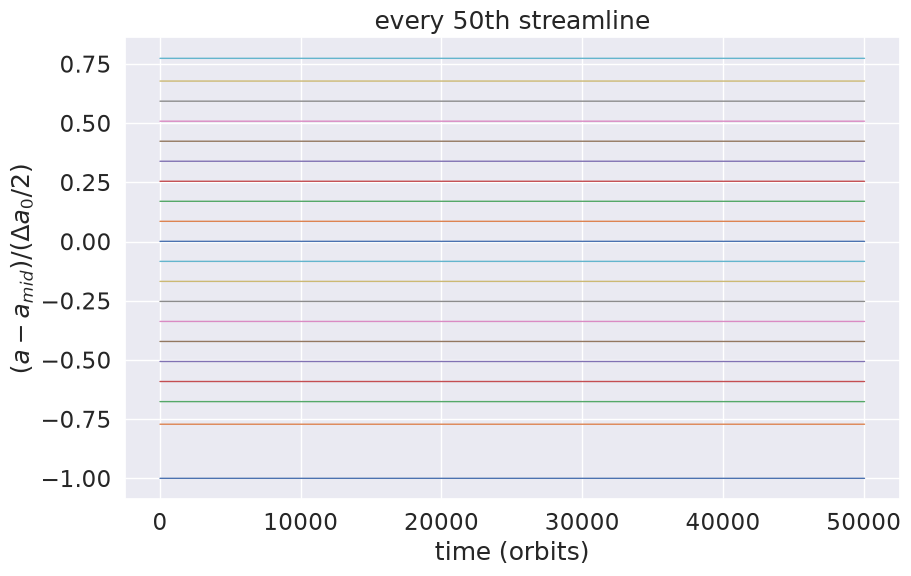

In [5]:
#plot streamlines' a-evolution, as in tests/spreading
f, ax = plt.subplots(figsize=(10, 6))
a_mid = A[0].mean()
da_0 = (A[0, -1] - A[0, 0])/2
for j in range(0, number_of_streamlines, 50):
    p = ax.plot(orbits[:N], (A[:, j] - a_mid)/da_0, linestyle='-', linewidth=1)
p = ax.set_xlabel('time (orbits)')
p = ax.set_ylabel(r'$(a - a_{mid})/(\Delta a_0/2)$')
p = ax.set_title('every 50th streamline')

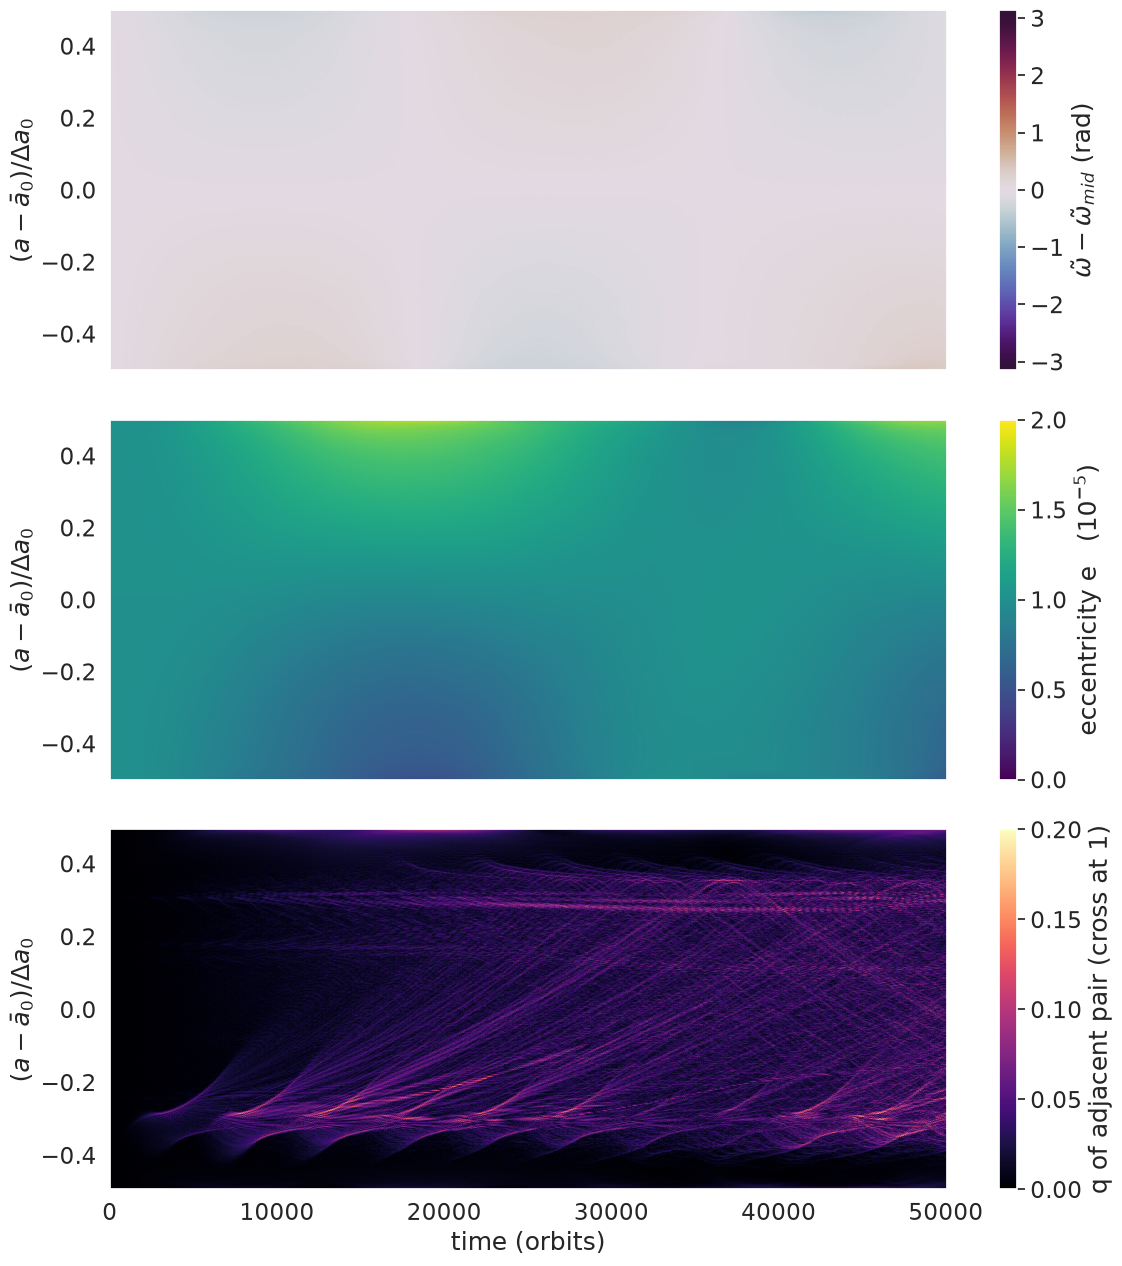

In [6]:
#space-time diagrams: each streamline's periapse (relative to the middle streamline's), eccentricity,
#and the nonlinearity q of each adjacent pair, versus time and semimajor axis
Tm = np.repeat(orbits[:N, None], number_of_streamlines, axis=1)
Ya = (A - A[0].mean())/(A[0, -1] - A[0, 0])
f, axs = plt.subplots(3, 1, figsize=(12, 13), sharex=True)
w_rel = (W + np.pi) % (2*np.pi) - np.pi
im = axs[0].pcolormesh(Tm, Ya, w_rel, cmap='twilight_shifted', vmin=-np.pi, vmax=np.pi, shading='gouraud')
p = f.colorbar(im, ax=axs[0], label=r'$\tilde{\omega} - \tilde{\omega}_{mid}$ (rad)')
im = axs[1].pcolormesh(Tm, Ya, E/1.0e-5, cmap='viridis', vmin=0, vmax=2, shading='gouraud')
p = f.colorbar(im, ax=axs[1], label=r'eccentricity e   ($10^{-5}$)')
im = axs[2].pcolormesh(Tm[:, :-1], 0.5*(Ya[:, 1:] + Ya[:, :-1]), q_pair, cmap='magma', vmin=0, vmax=0.2,
                       shading='gouraud')
p = f.colorbar(im, ax=axs[2], label='q of adjacent pair (cross at 1)')
for ax in axs:
    p = ax.set_ylabel(r'$(a - \bar{a}_0)/\Delta a_0$')
p = axs[2].set_xlabel('time (orbits)')
f.tight_layout()

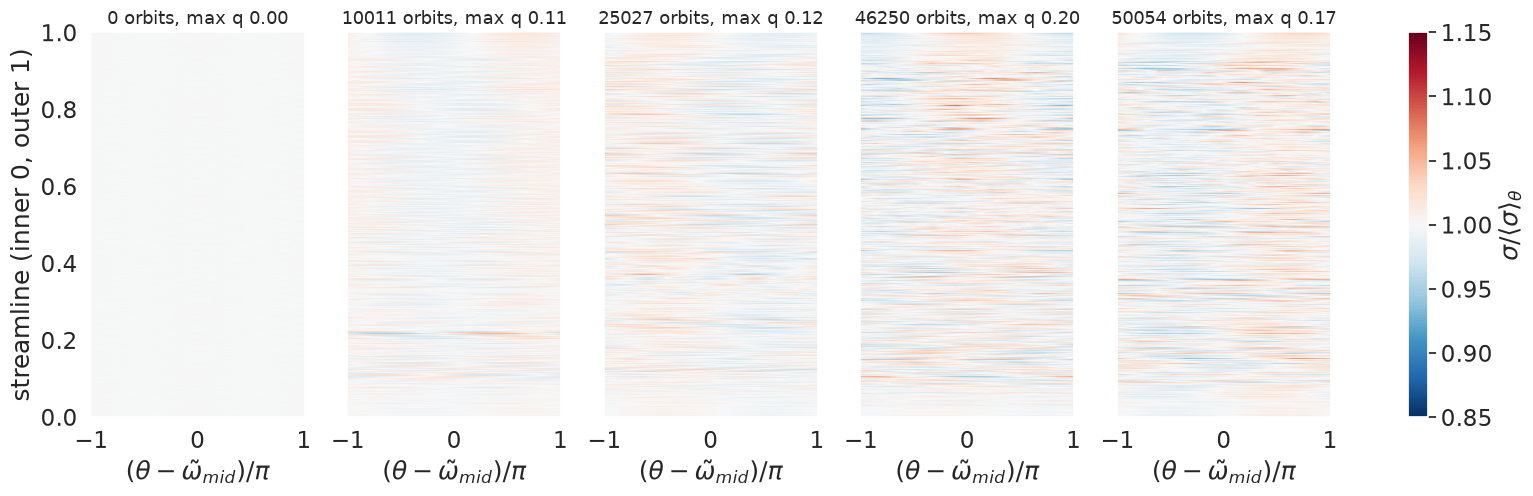

In [7]:
#surface density map: each particle's sigma (as the code computes it) over its streamline's longitude-averaged
#sigma, versus longitude measured from the middle streamline's periapse, at key moments: the start, 1e4 orbits,
#halfway, at max q, and the end
def sigma_map(k, nth=181):
    lam = get_lambda(total_ring_mass, number_of_streamlines, J2, Rp, r[k], t[k], vr[k], vt[k])
    rw, tw, lw = wrap_ring(r[k]), wrap_ring(t[k], longitude=True), wrap_ring(lam)
    sd = surface_density(lw, delta_f(rw, tw))[:, 1:-1]
    th = np.linspace(-np.pi, np.pi, nth)
    smap = np.empty((number_of_streamlines, nth))
    for j in range(number_of_streamlines):
        x = (t[k, j] - W[k, number_of_streamlines//2] + np.pi) % (2*np.pi) - np.pi
        o = np.argsort(x)
        smap[j] = np.interp(th, x[o], (sd[j]/sd[j].mean())[o], period=2*np.pi)
    return th, smap

qmax = q_pair.max(axis=1)
k_max = int(qmax.argmax())
key = sorted({0, int(np.searchsorted(orbits, 1.0e4)), (N - 1)//2, k_max, N - 1})
f, axs = plt.subplots(1, len(key), figsize=(4*len(key), 5), sharey=True)
y = np.arange(number_of_streamlines)/(number_of_streamlines - 1)
for ax, k in zip(axs, key):
    th, smap = sigma_map(k)
    im = ax.pcolormesh(th/np.pi, y, smap, cmap='RdBu_r', vmin=0.85, vmax=1.15, shading='nearest')
    p = ax.set_title(f'{orbits[k]:.0f} orbits, max q {qmax[k]:.2f}', fontsize=13)
    p = ax.set_xlabel(r'$(\theta - \tilde{\omega}_{mid})/\pi$')
p = axs[0].set_ylabel('streamline (inner 0, outer 1)')
p = f.colorbar(im, ax=axs, label=r'$\sigma/\langle\sigma\rangle_\theta$')

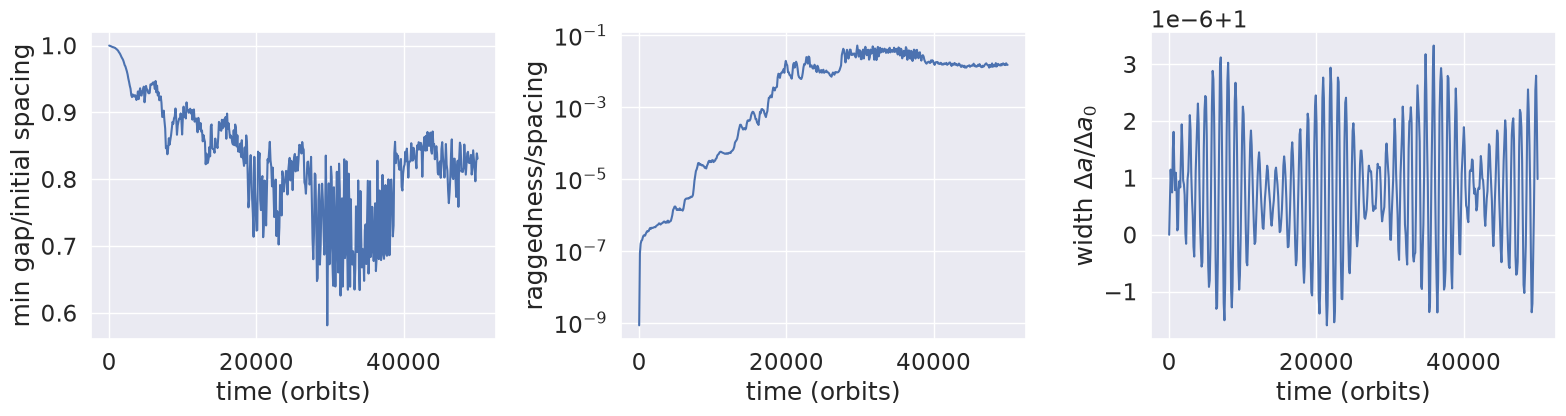

In [8]:
#ringlet health: smallest gap between adjacent streamlines, raggedness, and width versus time
f, axs = plt.subplots(1, 3, figsize=(16, 4.5))
p = axs[0].plot(orbits[:N], gap)
p = axs[0].set_ylabel('min gap/initial spacing')
p = axs[1].semilogy(orbits[:N], ragged)
p = axs[1].set_ylabel('raggedness/spacing')
p = axs[2].plot(orbits[:N], width)
p = axs[2].set_ylabel(r'width $\Delta a/\Delta a_0$')
for ax in axs:
    p = ax.set_xlabel('time (orbits)')
f.tight_layout()

In [9]:
#optional: animation, one frame per two outputs, into the git-ignored figs/ as periapse.gif and as an HTML player
#(periapse.html, with a pause button): each streamline's eccentricity and periapse relative to that of streamline 1 (just exterior to the innermost)
#versus its distance from the middle streamline, and q of each adjacent pair; a ringlet that precesses as rigid
#sub-ringlets shows flat steps. About 1 min; set make_animation = True to make it
make_animation = False
if make_animation:
    from matplotlib import animation
    os.makedirs('figs', exist_ok=True)
    #the animation as a GIF, and as an HTML page with play/pause/step controls
    def save(anim, name):
        anim.save(name + '.gif', writer='pillow', fps=10, dpi=60)
        anim.save(name + '.html', writer=animation.HTMLWriter(fps=10, embed_frames=True, default_mode='loop'), dpi=60)
    plt.rcParams['animation.embed_limit'] = 500                          #MB; the default 20 drops frames
    #time also in units of the viscous spreading timescale tau_nu = Delta a_0^2/12 nu_s (hahn25 Eq. 9), if viscous
    tau_nu = (A[0, -1] - A[0, 0])**2/(12*shear_viscosity)/(2*np.pi) if shear_viscosity > 0 else None   #orbits
    def when(k):
        o = orbits[k]
        ex = int(np.floor(np.log10(o))) if o > 0 else 0
        return rf'$t = {o/10**ex:.2f}\times10^{{{ex}}}$ orbits' + (rf' $= {o/tau_nu:.3f}\,\tau_\nu$' if tau_nu else '')
    #eccentricity and periapse (relative to streamline 1's) profiles, into figs/periapse.gif
    f, (ax0, ax1, ax2) = plt.subplots(1, 3, figsize=(18, 6))
    f.subplots_adjust(left=0.05, right=0.98, wspace=0.3)
    mid = number_of_streamlines//2
    x = (A - A[:, mid:mid + 1])/(A[0, -1] - A[0, 0])
    e4 = E
    w_in = ((W - W[:, 1:2] + np.pi)%(2*np.pi) - np.pi)/np.pi     #relative to streamline 1 (just exterior to the innermost), in [-1, 1)
    line0, = ax0.plot(x[0], e4[0], color='0.5', linewidth=1)
    dots0 = ax0.scatter(x[0], e4[0], color='C0', s=12, zorder=3)
    p = ax0.set_xlim(x.min(), x.max())
    p = ax0.set_ylim(0, 1.05*e4.max())
    p = ax0.set_xlabel(r'$(a - a_{mid})/\Delta a_0$')
    p = ax0.set_ylabel(r'$e$')
    line1, = ax1.plot(x[0], w_in[0], color='0.5', linewidth=1)
    dots1 = ax1.scatter(x[0], w_in[0], color='C0', s=12, zorder=3)
    p = ax1.set_xlim(x.min(), x.max())
    p = ax1.set_ylim(-1, 1)
    p = ax1.axhline(0, color='0.8', linewidth=0.8)
    p = ax1.set_xlabel(r'$(a - a_{mid})/\Delta a_0$')
    p = ax1.set_ylabel(r'$(\tilde{\omega} - \tilde{\omega}_1)/\pi$')
    xq = 0.5*(x[:, 1:] + x[:, :-1])                            #q of each adjacent pair, at the pair's midpoint
    line2, = ax2.plot(xq[0], q_pair[0], color='0.5', linewidth=1)
    dots2 = ax2.scatter(xq[0], q_pair[0], color='C0', s=12, zorder=3)
    p = ax2.set_xlim(x.min(), x.max())
    p = ax2.set_ylim(0, 1.05*q_pair[:N].max())
    p = ax2.set_xlabel(r'$(a - a_{mid})/\Delta a_0$')
    p = ax2.set_ylabel(r'$q$')
    title = f.suptitle('')
    def update(k):
        line0.set_data(x[k], e4[k])
        dots0.set_offsets(np.c_[x[k], e4[k]])
        line1.set_data(x[k], w_in[k])
        dots1.set_offsets(np.c_[x[k], w_in[k]])
        line2.set_data(xq[k], q_pair[k])
        dots2.set_offsets(np.c_[xq[k], q_pair[k]])
        title.set_text(when(k))
        return line0, dots0, line1, dots1, line2, dots2, title
    save(animation.FuncAnimation(f, update, frames=range(0, N, 2)), 'figs/periapse')
    plt.close(f)
from IPython.display import IFrame
if os.path.exists('figs/periapse.html'):
    display(IFrame('figs/periapse.html', width=1120, height=480))

max |delta L/L_0| =  1.658816415901062e-11


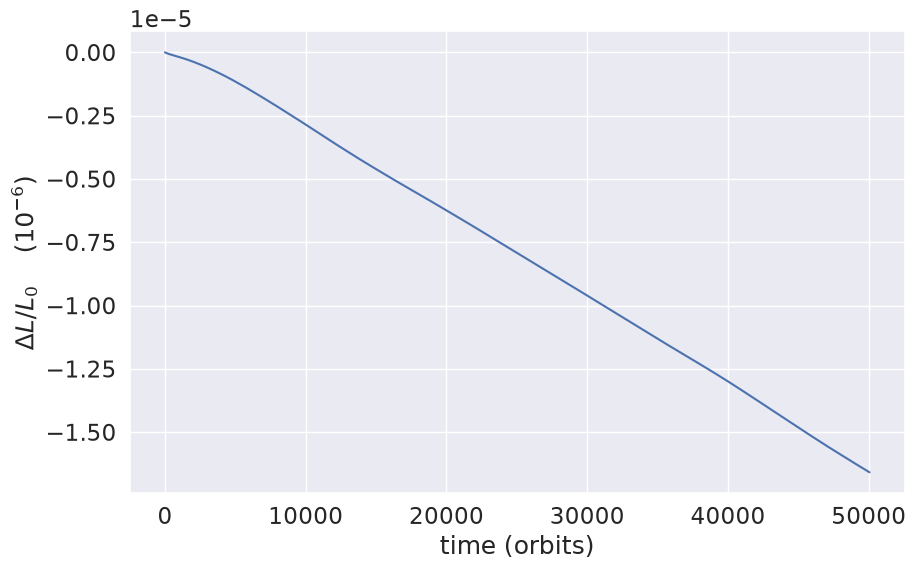

In [10]:
#total angular momentum in the barycentric frame, as in tests/spreading
particle_mass = total_ring_mass/(number_of_streamlines*particles_per_streamline)
L = []
for k in range(N):
    r_bc, t_bc, vr_bc, vt_bc, r_0, t_0, vr_0, vt_0 = planeto2bary(total_ring_mass, r[k], t[k], vr[k], vt[k])
    L += [1.0*r_0*vt_0 + np.sum(particle_mass*r_bc*vt_bc)]
L = np.array(L)
delta_L = (L - L[0])/L[0]
print('max |delta L/L_0| = ', np.abs(delta_L).max())
f, ax = plt.subplots(figsize=(10, 6))
p = ax.plot(orbits[:N], delta_L/1.0e-6)
p = ax.set_ylabel(r'$\Delta L/L_0$    $(10^{-6})$')
p = ax.set_xlabel('time (orbits)')

In [11]:
#is the nominal ringlet well behaved?
i10, i90 = int(0.1*number_of_streamlines), int(0.9*number_of_streamlines)
twist = np.abs(W[:, i90] - W[:, i10])
print('max twist of the middle 80% (rad) = ', twist.max())
checks = {
    'no NaN': N == len(times) and monitor['nan_timestep'] is None,
    'no crossing': monitor['streamline_crossing_timestep'] is None and gap.min() > 0,
    'q < 0.5 (not wound up by J2)': q.max() < 0.5,
    'twist of the middle 80% < 1 rad (J2 alone: ~5)': twist.max() < 1.0,
    'smooth: raggedness < 0.1 spacings': ragged.max() < 0.1,
}
for name, ok in checks.items():
    print('PASS' if ok else 'FAIL', ' ', name)
assert all(checks.values())

max twist of the middle 80% (rad) =  0.3816860403910258
PASS   no NaN
PASS   no crossing
PASS   q < 0.5 (not wound up by J2)
PASS   twist of the middle 80% < 1 rad (J2 alone: ~5)
PASS   smooth: raggedness < 0.1 spacings
